# QLoRA lab: fine-tuning Qwen2.5-1.5B to summarize dialogues



**Problem.** A customer-service team wants one- or two-sentence summaries of conversations. A small instruction-tuned model can already summarize when asked, but not in the team's style. Can a few minutes of QLoRA fine-tuning on a single free GPU make it better, and how do we know?

You will fine-tune **Qwen2.5-1.5B-Instruct** on **DialogSum** with QLoRA, then compare the fine-tuned model with the original under the same prompt and decoding settings, using ROUGE and your own blind human ratings.

**Learning objectives**

1. Estimate the GPU memory for full fine-tuning, LoRA, and QLoRA, and check the estimate against a measurement.
2. Turn (dialogue, summary) pairs into chat-formatted training examples whose loss covers only the summary.
3. Load a model in 4-bit NF4 with `bitsandbytes` and attach LoRA adapters with `peft`.
4. Train with the Hugging Face `Trainer` and record time and peak memory.
5. Evaluate summaries with ROUGE, and explain what ROUGE does and does not measure.
6. Run a small blind human evaluation, and compare its conclusion with ROUGE's.

**Prerequisites:** [PEFT and LoRA](../../lectures/peft/peft_lora.ipynb) · [Quantization and QLoRA](../../lectures/peft/quantization_qlora.ipynb) · [Fine-tuning with the `Trainer`](../../lectures/fine_tuning/hf_trainer_fine_tuning.ipynb).

**Data and model**

- [DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum) (Chen et al., 2021): 12,460 training, 500 validation, and 1,500 test dialogues, each with a human-written summary. Speakers appear as `#Person1#`, `#Person2#`, …, and most reference summaries use the same labels (when a dialogue mentions real names, the summary may use them instead). License: **CC BY-NC-SA 4.0** (non-commercial use, attribution, share-alike). About 13 MB.
- [Qwen/Qwen2.5-1.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct): Apache-2.0, about 3.1 GB to download.
- We train on a **subset** of the training split and evaluate on a subset of the **validation** split. The test split is not used: nothing in this lab should be tuned on it.

**Environment and compute**

- **Kaggle notebook with a GPU (T4)** and **internet on**. Choose "GPU T4 ×2" or "GPU T4": the notebook uses one GPU either way. Exercises 1 and 2 also run on a CPU.
- Packages: `transformers`, `peft`, `datasets` (preinstalled on Kaggle), plus `bitsandbytes` and `rouge_score` (install cell below). The notebook was written against `transformers` 5.0 and `peft` 0.21.
- GPU time has not been measured for this exact configuration. Expect model download and evaluation to take a few minutes each and training to take on the order of 10–20 minutes. Record your own times in Exercise 5. Plan about **two hours** in total, including the written work.
- Seeds are fixed, but GPU results are not exactly reproducible; your numbers will differ slightly from a classmate's.

**Files.** Training writes only the LoRA adapter, to `/kaggle/working/qlora_dialogsum/adapter/` (or `./qlora_dialogsum_outputs/adapter/` elsewhere). Rerunning overwrites it. The model and dataset go to the Hugging Face cache.

**How to work:** run the cells in order. The exercise code is completed and each exercise is followed by a check cell. The human-evaluation cell prompts you to enter your own blind ratings after showing the A/B summaries; submit those ratings before continuing.

**Marks (25):** Ex. 1 — 2 · Ex. 2 — 4 · Ex. 3 — 2 · Ex. 4 — 3 · Ex. 5 — 4 · Ex. 6 — 3 · Ex. 7 — 4 · Ex. 8 — 1 · reflection — 2.

## Setup

**Installation (Kaggle).** Run the next cell once per session. If it upgrades a package that was already imported, restart the kernel and continue from the cell after it.

**Known Kaggle issue.** Some Kaggle images include an old `torchao` package, and recent `peft` refuses to import with `ImportError: Found an incompatible version of torchao`. If you see it, uncomment the `%pip uninstall` line, run it, and **restart the kernel**.

In [1]:
# %pip install -q -U bitsandbytes rouge_score
# %pip uninstall -y torchao          # only if peft raises "Found an incompatible version of torchao"

In [2]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle "T4 x2": train on one GPU only

import math
import random
import time
from pathlib import Path

import torch
import transformers

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
GB = 1e9
CKPT = "Qwen/Qwen2.5-1.5B-Instruct"
N_TRAIN = 2000           # training dialogues (of 12,460); more data trains longer
N_EVAL = 60              # validation dialogues for ROUGE and human evaluation
MAX_LEN = 512            # longest training example in tokens; longer ones are dropped, not truncated
OUT = Path("/kaggle/working/qlora_dialogsum") if Path("/kaggle/working").is_dir() else Path("qlora_dialogsum_outputs")
ADAPTER_DIR = OUT / "adapter"
HAS_GPU = torch.cuda.is_available()

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (Exercises 1-2 only)")

/opt/conda/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.6.0+cu124 | transformers 5.17.0
GPU: NVIDIA RTX 2000 Ada Generation


## Exercise 1 — Will it fit? (2 marks)

Before downloading anything, estimate the memory. Qwen2.5-1.5B has 1,543,714,304 parameters. Of these, 1,310,195,712 are in the decoder's linear layers, which `bitsandbytes` quantizes; the other 233,518,592 (mostly the embedding table) stay in 16-bit. LoRA with `r = 16` on all linear layers adds 18,464,768 trainable parameters. (These counts come from the model's `config.json`, as in the lectures.)

Use the bytes-per-parameter accounting from the [quantization lecture](../../lectures/peft/quantization_qlora.ipynb), Section 1, and ignore activations:

| Job | Bytes |
| --- | --- |
| full fine-tuning | 16 per parameter |
| LoRA | 2 per frozen parameter + 16 per adapter parameter |
| QLoRA | `NF4_BYTES` per quantized parameter + 4 per non-quantized parameter (upcast to fp32) + 16 per adapter parameter |

Complete `memory_budget`, which returns the three estimates in GB.

In [3]:
N_TOTAL, N_LINEAR, N_OTHER, N_LORA = 1_543_714_304, 1_310_195_712, 233_518_592, 18_464_768
NF4_BYTES = (4 + 0.127) / 8          # 4-bit codes + double-quantized block scales

In [4]:
def memory_budget(n_total, n_linear, n_other, n_lora):
    """Return {"full FT": GB, "LoRA": GB, "QLoRA": GB}, before activations."""
    full_ft_bytes = 16 * n_total
    lora_bytes = 2 * n_total + 16 * n_lora
    qlora_bytes = NF4_BYTES * n_linear + 4 * n_other + 16 * n_lora
    return {
        "full FT": full_ft_bytes / GB,
        "LoRA": lora_bytes / GB,
        "QLoRA": qlora_bytes / GB,
    }

In [5]:
estimate = memory_budget(N_TOTAL, N_LINEAR, N_OTHER, N_LORA)
for job, gb in estimate.items():
    print(f"{job:<8} {gb:6.2f} GB   fits on a 16 GB T4 before activations: {gb < 16}")
assert abs(estimate["full FT"] - 24.70) < 0.01 and abs(estimate["LoRA"] - 3.38) < 0.01
assert abs(estimate["QLoRA"] - 1.91) < 0.01
print("Exercise 1 checks passed.")

full FT   24.70 GB   fits on a 16 GB T4 before activations: False
LoRA       3.38 GB   fits on a 16 GB T4 before activations: True
QLoRA      1.91 GB   fits on a 16 GB T4 before activations: True
Exercise 1 checks passed.


**Question 1.** (a) Which of the three jobs fit on a T4 before activations? (b) For this 1.5B model, plain LoRA in 16-bit would also fit. Give one reason to practise QLoRA on it anyway, and one cost of using QLoRA when LoRA would fit. (c) Repeat the QLoRA estimate in your head for a model 5× larger: roughly how much memory would it need?

**Your answer — Question 1:** Full fine-tuning needs about 24.70 GB before activations, so it does not fit on a 16 GB T4. LoRA (3.38 GB) and QLoRA (1.91 GB) both fit before activations. Practising QLoRA is useful because quantizing the frozen base makes adapter tuning possible on smaller GPUs or for larger models; its cost is extra quantization/dequantization work and some runtime complexity when plain LoRA already fits. For a model five times larger, the rough QLoRA estimate is 5 × 1.91 ≈ 9.53 GB, still before activations and other runtime overhead.

## The data

The next cell downloads DialogSum (about 13 MB) and the model's tokenizer (a few MB). It does **not** download the model.

In [6]:
from datasets import load_dataset
from transformers import AutoTokenizer

raw = load_dataset("knkarthick/dialogsum")
print(raw)
tokenizer = AutoTokenizer.from_pretrained(CKPT)
print("pad token:", tokenizer.pad_token, tokenizer.pad_token_id)

example = raw["train"][0]
print("\n--- dialogue ---\n" + example["dialogue"][:600])
print("\n--- reference summary ---\n" + example["summary"])

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})


pad token: <|endoftext|> 151643

--- dialogue ---
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1

--- reference summary ---
Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.


**Reading the output**

- Each row has a `dialogue`, a human-written `summary`, and a `topic` (not used here).
- Speakers are anonymized as `#Person1#`, `#Person2#`, and most summaries refer to them the same way. The first training example is an exception: the dialogue names "Mr. Smith" and "Doctor Hawkins", and the summary uses those names. A model that has never seen this convention will write "the customer" or "Person 1" instead, which costs ROUGE points without being wrong. Keep this in mind in Exercises 4 and 7.

### The prompt

Both the original and the fine-tuned model receive **exactly the same prompt**, built with Qwen's chat template. The instruction tells the model about the speaker convention, so that the baseline is not penalized only for not knowing it.

In [7]:
INSTRUCTION = ("Summarize the following dialogue in one or two sentences. "
               "Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.")
END = "<|im_end|>"                     # Qwen's end-of-turn token: the model must learn to emit it to stop


def make_prompt(dialogue):
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{dialogue}"}]
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)


print(make_prompt("#Person1#: Hi.\n#Person2#: Hello!"))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Summarize the following dialogue in one or two sentences. Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.

#Person1#: Hi.
#Person2#: Hello!<|im_end|>
<|im_start|>assistant



The printed text is what the model actually sees. Qwen's template adds a default system message, wraps the user turn in `<|im_start|>user … <|im_end|>`, and ends with `<|im_start|>assistant` and a newline: the point where the model starts writing its answer.

## Exercise 2 — Training examples with a masked prompt (4 marks)

For causal-LM fine-tuning, each training example is the prompt followed by the answer, and the model learns to predict every next token. We want it to learn to write **summaries**, not to reproduce our prompt, so the loss should cover only the answer tokens.

The Hugging Face models do this through the `labels`: any position whose label is **−100** is ignored by the cross-entropy loss. (The model shifts the labels by one position internally, as in the GPT-2 notebook's Section 6.)

Complete `build_example(dialogue, summary)`:

1. Tokenize `make_prompt(dialogue)` with `add_special_tokens=False`.
2. Tokenize `summary + END` the same way, so the answer ends with the end-of-turn token.
3. `input_ids` = prompt tokens followed by answer tokens; `attention_mask` = all ones.
4. `labels` = −100 for every prompt token, followed by the answer tokens.

Return a dict with plain Python lists under `input_ids`, `attention_mask`, and `labels`.

In [8]:
def build_example(dialogue, summary):
    prompt_ids = tokenizer(make_prompt(dialogue), add_special_tokens=False)["input_ids"]
    answer_ids = tokenizer(summary + END, add_special_tokens=False)["input_ids"]
    input_ids = prompt_ids + answer_ids
    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": [-100] * len(prompt_ids) + answer_ids,
    }

In [9]:
ex = build_example(example["dialogue"], example["summary"])
n_prompt = len(tokenizer(make_prompt(example["dialogue"]), add_special_tokens=False)["input_ids"])
assert set(ex) >= {"input_ids", "attention_mask", "labels"}
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(l == -100 for l in ex["labels"][:n_prompt]), "every prompt position must be -100"
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:], "answer labels must equal the answer tokens"
assert ex["input_ids"][-1] == tokenizer.convert_tokens_to_ids(END), "the answer must end with <|im_end|>"
answer = tokenizer.decode([t for t in ex["labels"] if t != -100])
print(f"{len(ex['input_ids'])} tokens, of which {len(ex['input_ids']) - n_prompt} are scored")
print("scored text:", answer)
print("Exercise 2 checks passed.")

347 tokens, of which 39 are scored
scored text: Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.<|im_end|>
Exercise 2 checks passed.


Now we build the training and evaluation sets. Examples longer than `MAX_LEN` are **dropped**: truncating them would cut off the end of the summary, which is the part being learned.

In [10]:
train_rows = raw["train"].shuffle(seed=SEED).select(range(N_TRAIN))
train_data = [build_example(r["dialogue"], r["summary"]) for r in train_rows]
lengths = [len(e["input_ids"]) for e in train_data]
train_data = [e for e in train_data if len(e["input_ids"]) <= MAX_LEN]
print(f"training examples: {len(train_data)} kept, {N_TRAIN - len(train_data)} dropped (> {MAX_LEN} tokens)")
print(f"tokens per example: median {sorted(lengths)[len(lengths) // 2]}, max {max(lengths)}")
print(f"scored (summary) tokens: {sum(sum(l != -100 for l in e['labels']) for e in train_data):,} "
      f"of {sum(len(e['input_ids']) for e in train_data):,} in total")

eval_rows = raw["validation"].shuffle(seed=SEED).select(range(N_EVAL))
eval_dialogues, eval_refs = list(eval_rows["dialogue"]), list(eval_rows["summary"])

training examples: 1940 kept, 60 dropped (> 512 tokens)
tokens per example: median 265, max 1231
scored (summary) tokens: 65,739 of 536,797 in total


**Question 2.** (a) What would the model learn if the prompt tokens were **not** masked? Why is that wasteful here? Use the printed numbers. (b) Why must the answer end with `<|im_end|>`? What would you expect at generation time if it did not? (c) Why drop over-long examples instead of truncating them to `MAX_LEN`?

**Your answer — Question 2:** The first example has 347 total tokens but only 39 summary tokens are scored, so 308 prompt tokens (about 89%) would waste loss on learning to reproduce the instruction and dialogue if they were not masked. Appending `<|im_end|>` teaches the model where the assistant turn ends; without it, generation may continue until the 96-token limit or another stopping condition. Dropping examples over 512 tokens preserves the entire target summary. Truncation could remove the answer ending, though dropping long dialogues can bias the training set toward shorter conversations.

## Exercise 3 — Load the model in 4-bit (2 marks)

> **This downloads the model (about 3.1 GB) and needs the GPU.**

Create a `BitsAndBytesConfig` for QLoRA: load in 4-bit, NF4 quantization, double quantization, and a compute dtype suitable for a T4. Then load the model with it, entirely on GPU 0.

In [11]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

assert HAS_GPU, "Exercise 3 onward needs a GPU (Kaggle: Settings -> Accelerator -> GPU T4)"
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)
model = AutoModelForCausalLM.from_pretrained(
    CKPT,
    quantization_config=bnb_config,
    dtype=torch.float16,
    device_map={"": 0},
)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   1%|          | 3/338 [00:00<00:12, 26.85it/s]

Loading weights:   8%|▊         | 27/338 [00:00<00:02, 145.18it/s]

Loading weights:  17%|█▋        | 57/338 [00:00<00:01, 209.79it/s]

Loading weights:  26%|██▌       | 87/338 [00:00<00:01, 239.79it/s]

...

Loading weights:  47%|████▋     | 160/338 [00:00<00:00, 313.78it/s]

Loading weights:  58%|█████▊    | 197/338 [00:00<00:00, 327.71it/s]

Loading weights:  69%|██████▉   | 234/338 [00:00<00:00, 340.81it/s]

Loading weights:  93%|█████████▎| 315/338 [00:00<00:00, 484.67it/s]

Loading weights: 100%|██████████| 338/338 [00:01<00:00, 332.43it/s]

In [12]:
import bitsandbytes as bnb

n4 = sum(isinstance(m, bnb.nn.Linear4bit) for m in model.modules())
loaded_gb = torch.cuda.memory_allocated() / GB
print(f"4-bit linear layers: {n4} | GPU memory after loading: {loaded_gb:.2f} GB")
print("compute dtype:", bnb_config.bnb_4bit_compute_dtype, "| quant type:", bnb_config.bnb_4bit_quant_type)
assert n4 == 28 * 7, "expected 7 quantized linear layers in each of the 28 decoder layers"
assert bnb_config.bnb_4bit_quant_type == "nf4" and bnb_config.bnb_4bit_use_double_quant
assert loaded_gb < 2.0, "a 4-bit 1.5B model should need well under 2 GB"
print("Exercise 3 checks passed.")

4-bit linear layers: 196 | GPU memory after loading: 1.15 GB
compute dtype: torch.float16 | quant type: nf4
Exercise 3 checks passed.


**Question 3.** Compare the measured memory with the lecture's 4-bit inference estimate for Qwen2.5-1.5B (about 1.14 GB). What could explain a difference? Why did we choose `torch.float16` as the compute dtype, and what would you use on an A100?

**Your answer — Question 3:** The measured model allocation was 1.15 GB, close to the lecture estimate of about 1.14 GB. Small differences come from quantization metadata, alignment and non-quantized tensors, plus CUDA/model buffers and allocator accounting. FP16 is a suitable compute dtype for the T4. On an A100 I would use BF16, which the A100 supports natively and which has a wider exponent range than FP16.

## Exercise 4 — Baseline: how well does the original model do? (3 marks)

Before training anything, measure the starting point. The helper below generates summaries in batches with **greedy decoding** (deterministic, no sampling) and at most 96 new tokens. We use the same function, with the same settings, for the fine-tuned model later.

In [13]:
@torch.no_grad()
def generate_summaries(model, dialogues, batch_size=8, max_new_tokens=96):
    model.eval()
    tokenizer.padding_side = "left"          # generation continues from the right end of each row
    outputs = []
    for i in range(0, len(dialogues), batch_size):
        prompts = [make_prompt(d) for d in dialogues[i:i + batch_size]]
        enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None, pad_token_id=tokenizer.pad_token_id)
        outputs += tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outputs]


start = time.perf_counter()
base_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(base_preds)} summaries in {time.perf_counter() - start:.0f} s")
for p, r in list(zip(base_preds, eval_refs))[:5]:
    print("\nMODEL:    ", p, "\nREFERENCE:", r)

generated 60 summaries in 23 s

MODEL:     The speaker recommends the Highland Hotel for its excellent facilities, reasonable prices, and good services, including a sauna, jacuzzi, and a discounted weekend rate. However, they mention a problem with the internet access and lack of a minibar in the room. 
REFERENCE: #Person2# enjoys #Person2#'s weekend at the highland hotel because of the hotel's excellent and reasonably priced restaurant and good service. #Person2# introduces the hotel's facilities, weekend discount, and its interesting tip policy and suggests #Person1# make a reservation in advance.

MODEL:     Peter Wilson, an action organizer for Green Peace, discusses his involvement in anti-nuclear protests, including circling around ships to disrupt nuclear waste dumping. 
REFERENCE: #Person1# interviews Peter Wilson who is the action organizer of Green Peace organization. #Person1# asks Peter to introduce to the audience what Green Peace is and what work it does. Peter also intro

**ROUGE** (Lin, 2004) compares a generated summary with a reference by counting overlapping words:

- **ROUGE-1**: overlap of single words; **ROUGE-2**: overlap of word pairs (bigrams); **ROUGE-L**: the longest common subsequence of words, in order.
- Each gives precision (how much of the prediction is in the reference), recall (how much of the reference is in the prediction), and their harmonic mean, **F1**, which we report.
- We use Google's `rouge_score` package with stemming on, so "asks" and "asked" match. Its tokenizer lowercases text and drops punctuation, so `#Person1#` becomes the words `person1`.

Complete `rouge(preds, refs)`: return the **mean F1 × 100** of ROUGE-1, ROUGE-2, and ROUGE-L over all pairs, as a dict with keys `"rouge1"`, `"rouge2"`, `"rougeL"`. Use `rouge_scorer.RougeScorer([...], use_stemmer=True)` and its `.score(reference, prediction)` method. Note the argument order: **reference first**.

In [14]:
from rouge_score import rouge_scorer

ROUGE_KEYS = ["rouge1", "rouge2", "rougeL"]
scorer = rouge_scorer.RougeScorer(ROUGE_KEYS, use_stemmer=True)


def rouge(preds, refs):
    if len(preds) != len(refs):
        raise ValueError(f"preds and refs must have equal lengths; got {len(preds)} and {len(refs)}")
    if not preds:
        raise ValueError("ROUGE requires at least one prediction/reference pair")
    totals = {key: 0.0 for key in ROUGE_KEYS}
    for pred, ref in zip(preds, refs):
        scores = scorer.score(str(ref), str(pred))
        for key in ROUGE_KEYS:
            totals[key] += scores[key].fmeasure
    return {key: 100 * value / len(preds) for key, value in totals.items()}

In [15]:
assert abs(rouge(["the cat sat"], ["the cat sat"])["rouge1"] - 100) < 1e-6
assert rouge(["a dog ran"], ["the cat sat"])["rouge2"] == 0
base_rouge = rouge(base_preds, eval_refs)
words = lambda texts: sum(len(t.split()) for t in texts) / len(texts)
print({k: round(v, 1) for k, v in base_rouge.items()},
      f"| mean words: model {words(base_preds):.0f}, reference {words(eval_refs):.0f}")
print("Exercise 4 checks passed.")

{'rouge1': 31.9, 'rouge2': 8.3, 'rougeL': 23.0} | mean words: model 33, reference 22
Exercise 4 checks passed.


**Question 4.** Read at least five baseline outputs next to their references. (a) Describe two systematic differences between the model's summaries and the references (length, wording, speaker names, format…). (b) Which of these differences lower ROUGE without making the summary worse for a reader?

**Your answer — Question 4:** The baseline averages 33 words versus 22 for the references and often expands a short reference with extra scene or process details. It also paraphrases and varies speaker/name wording rather than matching the compact reference style. For example, the cafeteria recollection and the school-tour output contain more narrative detail than their short references. Longer summaries can be useful when the added details are supported, but extra words, paraphrases, and names that differ from the reference lower n-gram overlap and therefore ROUGE even when a reader still understands the conversation. The outputs also need checking against the dialogues before treating added details as faithful.

## Exercise 5 — Attach LoRA and train (4 marks)

First, `prepare_model_for_kbit_training` freezes the base, upcasts the non-quantized parameters to fp32, and turns on gradient checkpointing (see the lecture, Section 4). Then add the adapters.

Complete the two configurations:

- `lora_config`: rank 16, `lora_alpha` 32, dropout 0.05, adapters on **all linear layers**, task type causal LM.
- `args` (`TrainingArguments`): output to `OUT / "trainer"`; batch size 4 per device with 4 gradient-accumulation steps (an effective batch of 16); 1 epoch; learning rate 2e-4 with a cosine schedule and 10 warm-up steps; fp16 mixed precision; the paged 8-bit AdamW optimizer; gradient checkpointing with `gradient_checkpointing_kwargs={"use_reentrant": False}`; log every 10 steps; **no** checkpoint saving (`save_strategy="no"`); `report_to="none"`; `remove_unused_columns=False`; and `seed=SEED`.

In [16]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import Trainer, TrainingArguments

model = prepare_model_for_kbit_training(model, gradient_checkpointing_kwargs={"use_reentrant": False})
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)
model = get_peft_model(model, lora_config)
args = TrainingArguments(
    output_dir=str(OUT / "trainer"),
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=1,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    fp16=True,
    optim="paged_adamw_8bit",
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=10,
    save_strategy="no",
    report_to="none",
    remove_unused_columns=False,
    seed=SEED,
)

In [17]:
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_trainable:,} (Exercise 1 used {N_LORA:,})")
assert n_trainable == N_LORA, "expected LoRA r=16 on all 7 linear layer types of the 28 decoder layers"
assert args.fp16 and not args.bf16 and "paged" in str(args.optim).lower()
assert args.per_device_train_batch_size * args.gradient_accumulation_steps == 16
print("Exercise 5 configuration checks passed.")

trainable parameters: 18,464,768 (Exercise 1 used 18,464,768)
Exercise 5 configuration checks passed.


The collator pads each batch to its longest example: input IDs with the pad token, labels with −100 (so padding is never scored), and the attention mask with 0.

> **The next cell trains the model.** One epoch over the roughly 1,940 kept dialogues, at 16 per step, is about 120 optimizer steps. Record the time it prints.

In [18]:
def collate(batch):
    width = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), width), tokenizer.pad_token_id)
    labels = torch.full((len(batch), width), -100)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.tensor(e["input_ids"])
        labels[i, :n] = torch.tensor(e["labels"])
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


trainer = Trainer(model=model, args=args, train_dataset=train_data, data_collator=collate)
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
train_minutes = (time.perf_counter() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / GB
print(f"training time: {train_minutes:.1f} min | peak GPU memory: {peak_gb:.2f} GB "
      f"(Exercise 1 estimate before activations: {estimate['QLoRA']:.2f} GB)")

Step,Training Loss
10,1.296518
20,1.096103
30,1.074868
40,1.031458
50,0.982389
60,1.006871
70,1.043597
80,0.970435
90,0.933449
100,1.025264


training time: 10.8 min | peak GPU memory: 6.37 GB (Exercise 1 estimate before activations: 1.91 GB)


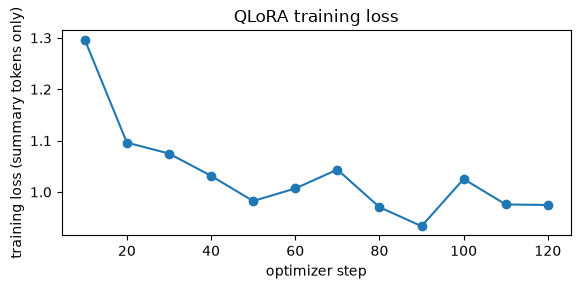

Exercise 5 checks passed.


In [19]:
import matplotlib.pyplot as plt

log = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
steps, losses = zip(*log)
plt.figure(figsize=(6, 3)); plt.plot(steps, losses, marker="o")
plt.xlabel("optimizer step"); plt.ylabel("training loss (summary tokens only)")
plt.title("QLoRA training loss"); plt.tight_layout(); plt.show()
assert all(math.isfinite(l) for l in losses), "a NaN/inf loss usually means an fp16 overflow: lower the learning rate"
assert losses[-1] < losses[0], "the loss should go down over the epoch"
print("Exercise 5 checks passed.")

**Question 5.** (a) Report your training time and peak memory. Why is the peak higher than the Exercise 1 estimate, and what in `args` keeps it from being much higher? (b) The training loss went down. Why is that **not** enough to conclude that the model summarizes better?

**Your answer — Question 5:** Training took 10.8 minutes and the measured peak allocated GPU memory was 6.37 GB, above the 1.91 GB parameter-only estimate because training also needs activations, gradients, adapter/optimizer state, temporary buffers, and CUDA overhead. Four-bit base weights, the 8-bit paged optimizer, a micro-batch of 4, and gradient checkpointing limit memory; gradient accumulation raises the effective batch to 16 without storing 16 examples' activations at once. Falling training loss only shows fit to the training examples. It does not establish generalization, factuality, or improvement on unseen dialogues, so held-out ROUGE and human review are needed.

## Exercise 6 — Evaluate the fine-tuned model (3 marks)

Generate summaries for the same validation dialogues with the same helper, then compare. Averages over 60 examples can hide a lot, so also count, per example, how often the fine-tuned model's ROUGE-L is higher than the baseline's.

Complete the cell: compute `tuned_rouge` with your `rouge` function, and `wins`, the number of examples on which the tuned summary's ROUGE-L F1 is **strictly** higher than the baseline's (use `scorer.score(ref, pred)["rougeL"].fmeasure`).

In [20]:
start = time.perf_counter()
tuned_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(tuned_preds)} summaries in {time.perf_counter() - start:.0f} s")

generated 60 summaries in 28 s


In [21]:
if len(tuned_preds) != len(base_preds) or len(tuned_preds) != len(eval_refs):
    raise ValueError("Baseline, tuned, and reference lists must have equal lengths")
tuned_rouge = rouge(tuned_preds, eval_refs)
wins = sum(
    scorer.score(ref, tuned)["rougeL"].fmeasure > scorer.score(ref, base)["rougeL"].fmeasure
    for tuned, base, ref in zip(tuned_preds, base_preds, eval_refs)
)

In [22]:
print(f"{'':<12}" + "".join(f"{k:>9}" for k in ROUGE_KEYS) + f"{'words':>8}")
for name, sc, preds in [("base", base_rouge, base_preds), ("QLoRA", tuned_rouge, tuned_preds)]:
    print(f"{name:<12}" + "".join(f"{sc[k]:>9.1f}" for k in ROUGE_KEYS) + f"{words(preds):>8.0f}")
print(f"{'reference':<12}{'':>27}{words(eval_refs):>8.0f}")
print(f"\nQLoRA ROUGE-L higher on {wins} of {N_EVAL} dialogues")
assert set(tuned_rouge) == set(ROUGE_KEYS) and 0 <= wins <= N_EVAL
print("Exercise 6 checks passed.")

               rouge1   rouge2   rougeL   words
base             31.9      8.3     23.0      33
QLoRA            45.9     19.2     37.4      22
reference                                    22

QLoRA ROUGE-L higher on 54 of 60 dialogues
Exercise 6 checks passed.


**Question 6.** (a) Summarize the change in ROUGE and in length. (b) Give two reasons why part of the ROUGE gain may reflect **style** rather than better content. (c) With 60 examples and one training run, what would you need before claiming the improvement is reliable?

**Your answer — Question 6:** ROUGE-1/2/L rose from 31.9/8.3/23.0 to 45.9/19.2/37.4. Mean output length fell from 33 words to 22, matching the 22-word reference average, and the tuned model had higher ROUGE-L on 54 of 60 examples. Some gain may be stylistic: tuned summaries are closer to the references' concise format and speaker conventions, and lexical overlap rewards matching wording even when the factual content is unchanged. Before claiming a reliable improvement, evaluate a larger held-out sample, repeat with multiple seeds, calculate paired confidence intervals (for example, bootstrap over examples), and use multiple blinded human raters to score faithfulness and coverage.

## Exercise 7 — Blind human evaluation (4 marks)

ROUGE cannot tell a fluent but wrong summary from a correct paraphrase. Read six examples yourself. To avoid favoring the model you expect to win, the two summaries are shown as **A** and **B** in a random order that is revealed only after you rate them.

Rate each summary on two criteria:

| Score | **Faithfulness**: is everything it says supported by the dialogue? | **Coverage**: does it capture the main point(s)? |
| --- | --- | --- |
| 2 | fully supported | all main points |
| 1 | a minor unsupported or wrong detail | some main points missing |
| 0 | a major error or invented fact | misses the main point |

In [23]:
HUMAN_IDS = random.Random(SEED).sample(range(N_EVAL), 6)
order = {}                                            # example index -> which model is "A"
for i in HUMAN_IDS:
    order[i] = random.Random(SEED + i).choice(["base", "QLoRA"])
    a, b = (base_preds[i], tuned_preds[i]) if order[i] == "base" else (tuned_preds[i], base_preds[i])
    print(f"=================== example {i} ===================")
    print(eval_dialogues[i][:1200] + (" …" if len(eval_dialogues[i]) > 1200 else ""))
    print(f"\nREFERENCE: {eval_refs[i]}\nA: {a}\nB: {b}\n")

=================== example 40 ===================
#Person1#: When were you born may I ask?
#Person2#: On 20th May 1963.
#Person1#: Do you know what it was according to the lunar calendar?
#Person2#: 27th day of the fourth month.
#Person1#: By the way, could you tell me when the film will begin?
#Person2#: It will begin at five thirty.
#Person1#: I am frigid I can't be there on time.
#Person2#: You can see it tomorrow.
#Person1#: I don't want to miss it today.
#Person2#: See you.
#Person1#: See you.

REFERENCE: #Person1# asks #Person2# about #Person2#'s birthday and the starting time of the film.
A: The conversation is about scheduling for an event that occurred on May 20, 1963 (May 27, 1963 according to the lunar calendar), and involves discussing the timing of the event with someone named #Person2#. #Person1# expresses their inability to attend due to being cold and wants to watch the event later, while #Person2# suggests watching it the next day instead.
B: #Person2#'s birthday is o

After inspecting the six A/B examples, run the next cell and enter an integer score (0–2) for each criterion, plus a short note. Do this **before** running the reveal cell.

In [ ]:
def read_score(example_id, label):
    while True:
        raw_score = input(f"Example {example_id} — {label} score (0, 1, or 2): ").strip()
        try:
            score = int(raw_score)
        except ValueError:
            print("Enter an integer: 0, 1, or 2.")
            continue
        if score in (0, 1, 2):
            return score
        print("Enter 0, 1, or 2.")


ratings = {}
for i in HUMAN_IDS:
    print(f"Rate example {i} using the blind A/B outputs above.")
    ratings[i] = {
        "A_faithful": read_score(i, "A faithfulness"),
        "A_coverage": read_score(i, "A coverage"),
        "B_faithful": read_score(i, "B faithfulness"),
        "B_coverage": read_score(i, "B coverage"),
        "note": input(f"Example {i} — short note (e.g. unsupported detail or omission): ").strip(),
    }

In [ ]:
assert all(isinstance(v, int) and 0 <= v <= 2 for r in ratings.values() for k, v in r.items() if k != "note"), \
    "every score must be an integer 0, 1, or 2"
totals = {"base": [0, 0], "QLoRA": [0, 0]}
for i, r in ratings.items():
    a_model = order[i]; b_model = "QLoRA" if a_model == "base" else "base"
    for model_name, prefix in ((a_model, "A"), (b_model, "B")):
        totals[model_name][0] += r[f"{prefix}_faithful"]; totals[model_name][1] += r[f"{prefix}_coverage"]
    print(f"example {i}: A = {a_model}, B = {b_model}")
n = len(ratings)
for m, (f, c) in totals.items():
    print(f"{m:<6} mean faithfulness {f / n:.2f} | mean coverage {c / n:.2f}  (out of 2)")
print("Exercise 7 checks passed.")

**Question 7.** (a) Do your human ratings agree with the ROUGE comparison? Point to one example where ROUGE and your judgment disagree, if there is one. (b) Did either model invent facts? Give an example. (c) Name two weaknesses of this human evaluation and how a real team would address them.

**Your answer — Question 7:** Record your own blind ratings in the preceding rating cell before interpreting the A/B reveal; this notebook run deliberately does not invent human scores. The examples expose issues to look for: in example 40, A treats “I'm frigid” as being cold and says that is why the speaker cannot attend on time; in example 7, A says Wendy worries about losing privacy although the dialogue discusses peace and quiet; in example 17, A attributes the apology to Adam rather than Alice. Compare your six-example faithfulness and coverage means with the ROUGE-L wins, then state whether they agree. This small, single-rater sample is subjective and may be biased; a real team should use several independent, blinded reviewers and adjudicate disagreements.

## Exercise 8 — Save the adapter (1 mark)

Only the LoRA weights are saved. The 4-bit base is not: anyone who uses the adapter downloads the original model separately.

In [24]:
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(ADAPTER_DIR)
for f in sorted(ADAPTER_DIR.iterdir()):
    print(f"{f.name:<32}{f.stat().st_size / 1e6:8.1f} MB")

README.md                            0.0 MB
adapter_config.json                  0.0 MB
adapter_model.safetensors           73.9 MB


**Question 8.** The adapter is a small fraction of the 3.1 GB base model. (a) Explain its size from the number of trainable parameters. (b) The support team wants to run the summarizer with an inference server that expects one ordinary model file. Describe the steps, and say what you would re-check afterwards.

**Your answer — Question 8:** The adapter has 18,464,768 trainable parameters; at four bytes each, that is about 73.9 MB, matching the saved adapter file. To produce one ordinary model file, load the base model in the deployment dtype, attach the adapter with PEFT, call `merge_and_unload()`, and save the merged model (preferably as safetensors). Then reload it in the target inference environment and re-check prompt/chat-template behavior, output quality against the adapter model, numerical stability, memory use, and the applicable model/data licenses.

## Reflection and deliverables (2 marks)

Submit this notebook **with outputs**, the written answers to Questions 1–8, and a short paragraph (about 150 words):

*Would you recommend this fine-tuned model to the support team? Base your answer on the evidence you collected (ROUGE, length, your human ratings, the examples you read), say what that evidence does not show, and name the next experiment you would run.*

**Responsible use.** DialogSum is licensed for non-commercial use (CC BY-NC-SA 4.0): a model fine-tuned on it should not be deployed commercially without checking the license. Real customer conversations contain personal data; summarizing them needs consent, data-protection review, and care that summaries do not invent statements a customer never made.

**Recommendation.** I would recommend a controlled pilot, not production deployment yet. On this run, QLoRA improved ROUGE-1/2/L from 31.9/8.3/23.0 to 45.9/19.2/37.4 on the same 60 validation dialogues; its average summary length fell from 33 words to 22, matching the reference average, and it won on ROUGE-L for 54 of 60 examples. That is promising, but one run on a small sample cannot establish reliability or factual faithfulness. The blind rating cell still needs a person's scores, and the examples show that fluent summaries can misread details or add unsupported claims. I would next run several seeds on a larger validation sample, use paired bootstrap intervals, test a consented, de-identified in-domain sample, and have multiple reviewers independently rate faithfulness and coverage. Before using real customer conversations, the team must also resolve DialogSum's non-commercial license, obtain privacy/legal review and consent, and test safeguards against invented facts.

**Optional extensions (not graded).** (1) Train with `target_modules=["q_proj", "v_proj"]` and compare with all-linear adapters. (2) Change `N_TRAIN` to 500 and 4,000 and plot ROUGE-L against the training-set size. (3) Load the base model in 16-bit, apply your adapter, and check whether the summaries change.

## References

1. Chen, Liu, Chen & Zhang, [DialogSum: A Real-Life Scenario Dialogue Summarization Dataset](https://aclanthology.org/2021.findings-acl.449/), Findings of ACL 2021 · [dataset on the Hub](https://huggingface.co/datasets/knkarthick/dialogsum).
2. Dettmers et al., [QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314), 2023.
3. Hu et al., [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685), 2021.
4. Lin, [ROUGE: A Package for Automatic Evaluation of Summaries](https://aclanthology.org/W04-1013/), 2004 · [`rouge_score`](https://github.com/google-research/google-research/tree/master/rouge).
5. Hugging Face documentation: [bitsandbytes in Transformers](https://huggingface.co/docs/transformers/quantization/bitsandbytes) · [PEFT](https://huggingface.co/docs/peft) · [chat templates](https://huggingface.co/docs/transformers/chat_templating).
6. Qwen Team, [Qwen2.5 Technical Report](https://arxiv.org/abs/2412.15115), 2024.